# V9: a public supervised ensemble toward leaderboard rank30

Gemma2-9B in original answer order and Llama3-8B in swapped order, using the
historical tascj recipe and equal weights. These models were trained on original
competition votes and external preference data. Local rows can overlap training;
local scores below are descriptive, not independent validation or a fair gain
estimate over our baseline. Only an official scored submission changes our
leaderboard evidence. Lower log loss is better.


In [1]:
import json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
PUB=REPO/'results/span_009';RUN=ROOT/'runs/span_009'
FIG=RUN/'figures';FIG.mkdir(parents=True,exist_ok=True)
def read(p):return json.loads(Path(p).read_text())
def save(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),dpi=160,bbox_inches='tight')
    plt.show()
q=read(PUB/'H54_qualification.json')
OUT=RUN/'jobs'/q['role']/'output/public_ensemble'
print('Audited exact source:',q['source']['kernel_version'])
print('Independent local quality:',q['independent_local_quality'])
print('CSV verified:',q['csv_verified'],'; both T4s:',q['both_t4_verified'])
display(pd.DataFrame(q['coverage']).T)


Audited exact source: arseniytrushin/llm-preference-span009-public-ensemble/4
Independent local quality: False
CSV verified: True ; both T4s: True


,rows,aligned_ensemble_replayed
uniform,256,True
long,64,True
test,3,True


## Measured inference cost and memory

The uniform256-row sample estimates full inference cost. The disjoint64 longest
character examples stress input length and memory. The conservative projection
uses25,000 hidden rows,20% margin, both cold starts and600seconds reserve.
Inspect long-example timing as well as the projection before submission.


,model,cohort,rows,seconds,seconds_per_row,max_tokens,gpu0_GiB,gpu1_GiB
0,m0,warmup,8,22.247568,2.780946,1380,10.023883,8.326364
1,m0,uniform,256,126.844343,0.495486,4330,10.219997,8.480394
2,m0,long,64,187.533965,2.930218,4330,10.144473,8.447413
3,m0,test,3,3.057184,1.019061,1951,9.753183,8.027287
4,m3,warmup,8,16.712216,2.089027,1361,8.056896,7.093974
5,m3,uniform,256,94.925216,0.370802,4330,8.253590,7.273775
6,m3,long,64,116.339910,1.817811,4333,8.217230,7.254296
7,m3,test,3,1.902581,0.634194,1816,7.774938,6.779040


Projected hidden hours: 7.494714030311995 ; gate: True


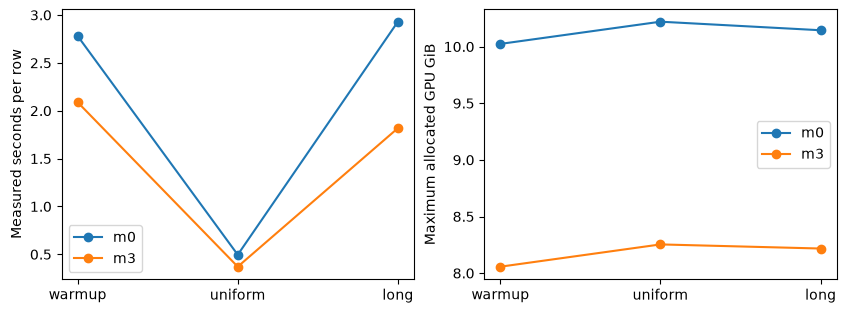

In [2]:
rows=[]
for role in q['measured_roles']:
    for cohort,r in role['cohorts'].items():
        rows.append({'model':role['role'],'cohort':cohort,'rows':r['rows'],
            'seconds':r['seconds'],'seconds_per_row':r['seconds']/r['rows'],
            'max_tokens':r['max_tokens'],'gpu0_GiB':r['peak_allocated_bytes'][0]/2**30,
            'gpu1_GiB':r['peak_allocated_bytes'][1]/2**30})
timing=pd.DataFrame(rows);display(timing)
print('Projected hidden hours:',q['runtime_projection_seconds']/3600,'; gate:',q['runtime_gate_passed'])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for model,g in timing[timing.cohort!='test'].groupby('model'):
    axes[0].plot(g.cohort,g.seconds_per_row,marker='o',label=model)
    axes[1].plot(g.cohort,g[['gpu0_GiB','gpu1_GiB']].max(axis=1),marker='o',label=model)
axes[0].set_ylabel('Measured seconds per row');axes[1].set_ylabel('Maximum allocated GPU GiB')
for ax in axes:ax.legend()
save(fig,'v9_inference_cost')


## Descriptive local predictions — training overlap possible

These scores are on the predeclared label-free profile cohorts after predictions
were frozen. They cannot establish generalization, and are not used to fit model
weights, ensemble weights or calibration. The long cohort is deliberately
unrepresentative. No target is an inference input.


In [3]:
from arena.span009_public import CLASSES
train=pd.read_csv(ROOT/'raw/train.csv',usecols=['id',*CLASSES]).set_index('id')
scores=[]
for cohort in ['uniform','long']:
    for model in ['m0','m3','ensemble']:
        a=np.load(OUT/(model+'_'+cohort+'.npz'));p=a['probabilities']
        if model=='m3':p=p[:,[1,0,2]]
        y=train.loc[a['ids'],CLASSES].to_numpy().argmax(1)
        scores.append({'cohort':cohort,'model':model,'rows':len(y),
            'descriptive_log_loss':float(-np.log(np.clip(p[np.arange(len(y)),y],1e-15,1)).mean()),
            'descriptive_accuracy':float((p.argmax(1)==y).mean()),'independent':False})
display(pd.DataFrame(scores))
print('Do not interpret these values as independent CV or a baseline gain.')


,cohort,model,rows,descriptive_log_loss,descriptive_accuracy,independent
0,uniform,m0,256,0.656236,0.734375,False
1,uniform,m3,256,0.565438,0.785156,False
2,uniform,ensemble,256,0.599429,0.773438,False
3,long,m0,64,0.907366,0.609375,False
4,long,m3,64,0.901251,0.546875,False
5,long,ensemble,64,0.896528,0.609375,False


Do not interpret these values as independent CV or a baseline gain.


## Failed startup, actual compute, and official outcome

Version1 failed before any cell because the old notebook engine needed explicit
kernel metadata; its charge and source are retained. Version2 fixes startup
without changing the inference recipe. Receipt elapsed time includes queue and
obfuscation and is not a GPU-time measurement. A pending official result is
displayed explicitly; notebook generation does not imply the rank goal is met.


In [4]:
charges=[]
for role in ['public_ensemble','public_ensemble_runtime_fix','public_ensemble_pipeline_fix','public_ensemble_resume']:
    r=read(PUB/'jobs'/role/'controller_state.json')
    charges.append({'attempt':role,'stage':r['stage'],'charged_seconds':r.get('charged_seconds')})
display(pd.DataFrame(charges))
for name in ['official_receipt.json','official_result.json','official_leaderboard.json']:
    p=PUB/name
    print(name,read(p) if p.exists() else 'Pending / not submitted')
print('Goal completion requires a fresh complete leaderboard observation with team17244411 rank<=30.')


,attempt,stage,charged_seconds
0,public_ensemble,failed,10.620
1,public_ensemble_runtime_fix,failed,414.992
2,public_ensemble_pipeline_fix,failed,895.742
3,public_ensemble_resume,complete,786.796


official_receipt.json {'ref': 58068582, 'message': ''}
official_result.json {'ref': 58068582, 'status': 'SubmissionStatus.PENDING', 'public_score': '', 'private_score': '', 'date': '2026-11-06 20:28:37.697000', 'description': 'Span009 frozen public tascj Gemma2/Llama3 equal ensemble; no local-quality claim'}
official_leaderboard.json Pending / not submitted
Goal completion requires a fresh complete leaderboard observation with team17244411 rank<=30.
